# JavaScript 基础第五天

对象、Math、随机数与数据渲染

## 课程说明

本日学习用对象集中描述一个事物：属性保存信息，方法封装行为；再把多个对象放进数组，遍历生成学生表和课程列表。随后学习 `Math`，完成随机点名、猜数字和随机颜色，最后认识基本类型与对象的赋值区别。

本篇依据[百度网盘课程资料](https://pan.baidu.com/s/1MxueOHXGQtmE-ypRq1kELA?pwd=9987)中的「JavaScript基础第五天」整理，提取码 `9987`。来源包括 55 页讲义、原 Markdown、XMind、13 份编号课堂 HTML、学成在线案例、配套素材以及全部作业题目和答案。课堂文件编号从 `06` 跳到 `08`，资料中没有编号 `07` 的文件。

标为“课堂原代码”或“资料参考答案”的内容保留变量、提示、注释和启用状态。通常摘录 HTML 的 `<script>`，涉及表格、课程列表和英雄图片的页面保留完整结构。整理示例与资料修正就地说明。所有代码作为 Markdown 展示，JavaScript 片段在 HTML 的 `<script>` 中练习，不在 Notebook 的 Python 内核中运行；不同示例分别执行，避免变量重名。图示及案例截图直接嵌入笔记，完整 HTML 中的 CSS 和图片路径仍按原资料目录组织。

## 0. 上节回顾：参数和返回值

当天第一个文件复习第四天的 `handleData`：布尔标记为 `true` 或省略时返回和，为 `false` 时返回平均值。

课堂原代码（`04-code/01-作业.html`）：

```javascript
    // function fn() {
    //   // return 20
    // }
    // let re = fn()
    // console.log(re)

    // 目标： 封装一个函数, 可以求任意数组的 和 或 平均值
    //要求：
    //- 函数可以传递2个参数，比如  handleData(arr, true)      handleData 处理数据的意思
    //- 参数一： 接受实参传递过来的数组
    //- 参数二: 布尔类型  如果是true或者不传递参数 是求和操作，   如果传递过来的参数是 false 则是求平均值
    function handleData(arr, flag = true) {
      let sum = 0
      for (let i = 0; i < arr.length; i++) {
        sum += arr[i]
      }
      // flag变量里面存的 布尔值

      if (flag) {
        // 求和
        // 返回值
        return sum
      } else {
        // 求平均值
        return sum / arr.length
      }
    }
    console.log(handleData([1, 2, 3, 4, 5], true))
    console.log(handleData([1, 2, 3, 4, 5]))
    console.log(handleData([1, 2, 3, 4, 5], false))

  
```

三次调用依次输出 `15`、`15`、`3`。计算放在函数内部，结果通过 `return` 交给调用者，输出发生在调用处。平均值要求数组非空；空数组求和为 `0`，求平均值会计算 `0 / 0`，得到 `NaN`。本日对象中的方法依然遵守这些函数规则。

## 1. 对象的声明与属性

### 1.1 为什么需要对象

对象是 JavaScript 的一种数据类型，用**属性名与值组成的键值对**集中描述事物。例如姓名、年龄、性别、家乡分别有名字，比散落的变量或只靠索引解释含义更清楚。

```javascript
let person = {
  name: '小明',
  age: 18,
  gender: '男',
  hometown: '河北省'
}
console.log(person.name)  // 小明
console.log(person.age)   // 18
```

| 数据组织 | 适合表达的内容 | 访问示例 |
| --- | --- | --- |
| 数组 | 按位置排列的一组数据 | `students[0]` |
| 普通对象 | 一个事物具有哪些信息 | `person.name` |
| 对象数组 | 多个事物，每个都有若干信息 | `students[0].name` |

讲义把对象称为“无序的数据集合”，这里重点是**通过属性名表达含义，不依赖连续索引**。现代 JavaScript 对属性枚举顺序有规则，不能理解成每次遍历顺序随机。数组也能保存不同类型的数据，区别不在于能否混合类型。

### 1.2 对象字面量与键值对

创建对象常用一对花括号，即对象字面量。讲义也展示 `new Object()`，本课程优先使用字面量。

```javascript
let user = {}
let another = new Object()
console.log(typeof user)  // object
```

对象内部写 `属性名: 值`，多个成员用英文逗号隔开。属性值可以是数字、字符串、布尔值、数组、另一个对象或函数。属性名通常省略引号；包含空格、连字符等特殊字符时需要加引号。

**讲义第 12 页修正：**属性名和值之间是英文冒号 `:`，不是总结页写的分号 `;`；多个属性之间才是逗号 `,`。

讲义第 13 页的商品对象练习，整理写法：

```javascript
let goods = {
  name: '小米10青春版',
  num: '100012816024',
  weight: '0.55kg',
  address: '中国大陆'
}
console.log(goods.name)  // 小米10青春版
```

商品编号虽然由数字字符组成，本例使用字符串保存；它表示标识，不是参与算术的数量。对象中的 `name` 是属性，外部的 `goods` 是保存对象的变量，二者角色不同。

### 1.3 属性的增、删、改、查

对于本日的普通对象，读取属性用点或方括号，赋值可新增或修改属性，删除使用 `delete`。

| 操作 | 写法 | 说明 |
| --- | --- | --- |
| 查 | `goods.name` | 读取对应值 |
| 改 | `goods.name = '小米10 PLUS'` | 已有属性重新赋值 |
| 增 | `goods.color = '粉色'` | 原先没有该属性，则新增 |
| 删 | `delete goods.weight` | 删除属性，不是把值改成空字符串 |

按讲义第 20 页任务，先修改商品名称，再增加颜色，依次输出属性值：

```javascript
let goods = {
  name: '小米10青春版',
  num: '100012816024',
  weight: '0.55kg',
  address: '中国大陆'
}
goods.name = '小米10 PLUS'
goods.color = '粉色'
console.log(goods.name, goods.num, goods.weight, goods.address, goods.color)
delete goods.weight
console.log(goods.weight)  // undefined
```

读取普通对象中不存在的属性通常得到 `undefined`，常见原因之一是名字拼错。删除整个属性与 `goods.weight = undefined` 也不同：后者仍保留属性，只是值为 `undefined`。

### 1.4 点语法与方括号语法

点后直接写固定属性名；方括号里可以写字符串，也可以写计算出属性名的变量或表达式。

```javascript
let obj = {
  'goods-name': '小米10青春版',
  num: '100012816024'
}
let key = 'num'
console.log(obj.num)            // 100012816024
console.log(obj['num'])         // 100012816024
console.log(obj[key])           // 100012816024
console.log(obj.key)            // undefined，查的是名字为 key 的属性
console.log(obj['goods-name'])  // 小米10青春版
```

`obj['num']` 里的引号表示字符串属性名；`obj[key]` 不加引号，是先读取变量 `key` 的值。**方括号内并非一定要加引号**，讲义第 23 页总结应结合第 22 页的动态访问规则理解。含连字符的名字不能写成 `obj.goods-name`，这会被当作减法表达式。

课堂原文件把以上访问方式和商品操作放在一起：

课堂原代码（`04-code/02-对象的使用.html`）：

```javascript
    // 1.声明对象
    // let pink = {
    //   uname: 'pink老师',
    //   age: 18,
    //   gender: '女'
    // }
    // // console.log(pink)
    // // console.log(typeof pink)
    // // 改 把性别的女改为男
    // pink.gender = '男'
    // console.log(pink)
    // // 增
    // pink.hobby = '足球'
    // console.log(pink)
    // // 删 (了解)
    // delete pink.age
    // console.log(pink)
    // // let num = 10
    // num = 20
    // console.log(num)
    // 1. 声明
    // console.log(window.name)
    let obj = {
      'goods-name': '小米10青春版',
      num: '100012816024',
      weight: '0.55kg',
      address: '中国大陆'
    }
    obj.name = '小米10 PLUS'
    obj.color = '粉色'
    // console.log(obj.name)
    console.log(obj.num)
    console.log(obj.weight)
    console.log(obj.address)
    console.log(obj.color)
    // console.log(obj.goods - name)
    // 查的另外一种属性：
    // 对象名['属性名']
    console.log(obj['goods-name'])


    // 查总结：
    // (1) 对象名.属性名  obj.age
    console.log(obj.num)
    // (2) 对象名['属性名']  obj['age']
    console.log(obj['num'])





    // // console.log(address)
    // // 2. 使用属性 查  对象名.属性名
    // console.log(obj.address)
    // console.log(obj.name)


  
```

当前原码依次输出 `100012816024`、`0.55kg`、`中国大陆`、`粉色`、`小米10青春版`、`100012816024`、`100012816024`。

**资料差异：**原对象保存商品名的键是 `'goods-name'`，后面的 `obj.name = '小米10 PLUS'` 新增了另一个名为 `name` 的属性，并没有修改 `'goods-name'`。要修改原来的商品名称，应写 `obj['goods-name'] = '小米10 PLUS'`。这里不能仅凭两者都叫“商品名”就认为它们是同一属性。

## 2. 对象的方法

### 2.1 方法本质是函数

数据描述信息称为属性，行为信息称为方法。方法本质是对象中值为函数的成员，可以传参、输出，也可以返回结果。调用方式是 `对象名.方法名()`，不要漏掉括号。

课堂原代码（`04-code/03-对象的方法.html`）：

```javascript
    let obj = {
      uname: '刘德华',
      // 方法
      song: function (x, y) {
        // console.log('冰雨')
        console.log(x + y)
      },
      dance: function () { }
    }
    // 方法调用 对象名.方法名
    // console.log(obj.song(1, 2))
    obj.song(1, 2)

    // document.write('123')
  
```

原码 `obj.song(1, 2)` 输出 `3`。`dance` 是空函数，当前没有调用；`song` 只有输出、没有 `return`，调用返回值为 `undefined`。若启用注释中的 `console.log(obj.song(1, 2))`，会先输出 `3`，再输出返回值 `undefined`。

整理练习给对象加入唱歌和跳舞方法，并调用：

```javascript
let person = {
  name: '小红',
  singing: function (songName) {
    console.log(`演唱：${songName}`)
  },
  dance: function () {
    console.log('开始跳舞')
  },
  sum: function (x, y) {
    return x + y
  }
}
person.singing('两只老虎')
person['dance']()
console.log(person.sum(1, 2))  // 3
```

`person.singing` 是取得函数，`person.singing(...)` 才是执行函数。方括号也可以访问方法，再跟调用括号。

### 2.2 动态添加方法与同名覆盖

对象创建后也可以增加属性或方法。原 Markdown 的动态追加示例误写 `user.['age'] = 18`，点与方括号不能这样连用。正确整理版：

```javascript
let user = {}
user.name = '小明'
user['age'] = 18
user.move = function () {
  console.log('移动一点距离...')
}
user.move()
```

同一个普通对象中，重复赋值同一属性名会更新原值，不会因为一个值是函数、另一个是数字就变成两个不同成员。声明对象字面量时重复写同名的普通成员，后者也会覆盖前者，应避免无意重名。

## 3. 遍历对象与对象数组

### 3.1 for...in：属性名与属性值

普通对象没有数组那样自动维护的 `length` 和连续下标，不能照搬 `i < obj.length`。本日使用 `for...in` 遍历属性名，再通过方括号访问值。

课堂原代码（`04-code/04-遍历对象.html`）：

```javascript
    // for in 我们不推荐遍历数组
    // let arr = ['pink', 'red', 'blue']
    // for (let k in arr) {
    //   console.log(k)  // 数组的下标 索引号  但是是字符串 '0'
    //   console.log(arr[k])  // arr[k]
    // }
    // 1. 遍历对象 for in   
    let obj = {
      uname: 'pink老师',
      age: 18,
      gender: '男'
    }
    // 2. 遍历对象
    for (let k in obj) {
      console.log(k) // 属性名  'uname'   'age'
      // console.log(obj.uname)
      // console.log(obj.k)
      // console.log(obj.'uname')
      // console.log(obj['uname'])   'uname'  === k
      console.log(obj[k])  // 输出属性值  obj[k]
    }
  
```

当前依次输出属性名和对应值：`uname` 与 `pink老师`、`age` 与 `18`、`gender` 与 `男`。循环中的 `k` 是字符串形式的属性名，`obj[k]` 才是属性值。`obj.k` 查的是字面名字 `k`，不是本次循环取得的名字。

```javascript
let obj = { name: '小明', age: 18 }
for (let k in obj) {
  console.log(k, obj[k])
}
```

补充：`for...in` 还可能枚举继承来的可枚举字符串属性，后续学习原型时再区分；当前例子使用简单对象字面量。数组优先用之前的数字索引 `for`，`for...in` 的数组键是字符串，还可能包含额外属性，不适合替代本日的数组遍历。

### 3.2 对象数组：先取对象，再取属性

把每位学生描述成一个对象，再把对象放进数组，既能按索引遍历学生，又能按名字读取每位学生的信息。

课堂原代码（`04-code/05-遍历数组对象.html`）：

```javascript
    let students = [
      { name: '小明', age: 18, gender: '男', hometown: '河北省' },
      { name: '小红', age: 19, gender: '女', hometown: '河南省' },
      { name: '小刚', age: 17, gender: '男', hometown: '山西省' },
      { name: '小丽', age: 18, gender: '女', hometown: '山东省' }
    ]
    for (let i = 0; i < students.length; i++) {
      // console.log(i)  // 下标索引号
      // console.log(students[i]) // 每个对象
      console.log(students[i].name)
      console.log(students[i].hometown)
    }
  
```

`students[i]` 是第 `i` 位学生对象，`students[i].name` 才是该学生姓名。当前输出姓名和家乡，依次为小明/河北省、小红/河南省、小刚/山西省、小丽/山东省；注释中的 `console.log(students[i])` 则输出整个对象。

| 表达式 | 结果含义 |
| --- | --- |
| `students` | 整个学生数组 |
| `students.length` | 学生数量 |
| `students[0]` | 第一位学生对象 |
| `students[0].name` | 第一位学生姓名 |
| `students[i].hometown` | 当前学生的家乡 |

### 3.3 案例：学生信息表

需求：根据对象数组生成表格，每个学生一行，列为序号、姓名、年龄、性别、家乡。

1. 保留表格的标题与表头。
2. 遍历学生数组，在模板字符串里填入当前对象的数据。
3. 写入每个 `<tr>`，序号显示 `i + 1`。
4. 保留表格结束标签，确保每一行的列数一致。

课堂文件保留完整 CSS 和页面结构：

课堂原代码（`04-code/06-渲染学生信息表.html`）：

```html
<!DOCTYPE html>
<html lang="en">

<head>
    <meta charset="UTF-8">
    <meta name="viewport" content="width=device-width, initial-scale=1.0">
    <title>Document</title>
    <style>
        table {
            width: 600px;
            text-align: center;
        }

        table,
        th,
        td {
            border: 1px solid #ccc;
            border-collapse: collapse;
        }

        caption {
            font-size: 18px;
            margin-bottom: 10px;
            font-weight: 700;
        }

        tr {
            height: 40px;
            cursor: pointer;
        }

        table tr:nth-child(1) {
            background-color: #ddd;
        }

        table tr:not(:first-child):hover {
            background-color: #eee;
        }
    </style>
</head>

<body>
    <h2>学生信息</h2>
    <p>将数据渲染到页面中...</p>

    <table>
        <caption>学生列表</caption>
        <tr>
            <th>序号</th>
            <th>姓名</th>
            <th>年龄</th>
            <th>性别</th>
            <th>家乡</th>
        </tr>
        <!-- script写到这里 -->
        <script>
            // 1. 数据准备
            let students = [
                { name: '小明', age: 18, gender: '男', hometown: '河北省' },
                { name: '小红', age: 19, gender: '女', hometown: '河南省' },
                { name: '小刚', age: 17, gender: '男', hometown: '山西省' },
                { name: '小丽', age: 18, gender: '女', hometown: '山东省' },
                { name: '晓强', age: 16, gender: '女', hometown: '蓝翔技校' }
            ]
            // 2. 渲染页面
            for (let i = 0; i < students.length; i++) {
                document.write(`
                <tr>
                    <td>${i + 1}</td>
                    <td>${students[i].name}</td>
                    <td>${students[i].age}</td>
                    <td>${students[i].gender}</td>
                    <td>${students[i].hometown}</td>
                </tr>
                `)
            }
        </script>
    </table>

</body>


</html>
```

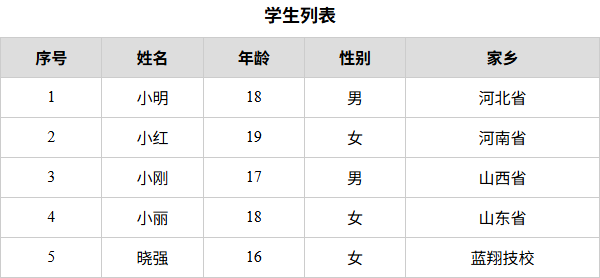

**资料差异：**讲义第 31 页的数据是四位学生，当前课堂文件追加了第五位「晓强」，共生成五条数据行。第五条的年龄、性别与家乡均按原码保留。配套 `06-素材/学生信息表素材.html` 是重复静态行的练习模板，完成时应将那些重复行替换为循环生成的行。

模板字符串中的 `${students[i].name}` 取得数据，`<td>` 提供结构，CSS 决定样式。表头和表尾放在循环外，重复行放在循环内；不要在每轮生成一张独立表格。

`document.write` 用于本课初始页面解析时的练习；页面加载完成后再调用可能覆盖页面，不宜当作后续交互更新方案。这里的数据来自固定课程数组；真实用户文本渲染还需要避免把文本当成 HTML 解释，后续 DOM 课程可用 `textContent` 等方式处理。

## 4. 内置对象 Math

### 4.1 属性与常用方法

`Math` 是 JavaScript 标准内置的数学对象，直接用 `Math.属性` 或 `Math.方法()`。`Math.PI` 是数值属性，不加调用括号；`Math.floor(...)` 等是方法，需要括号。

| 成员 | 用途 | 示例与结果 |
| --- | --- | --- |
| `Math.PI` | 圆周率 | 约 `3.141592653589793` |
| `Math.ceil(x)` | 向上取整 | `Math.ceil(1.1)` → `2` |
| `Math.floor(x)` | 向下取整 | `Math.floor(1.9)` → `1` |
| `Math.round(x)` | 取最近整数，正好中点时向正无穷方向取 | `Math.round(1.5)` → `2` |
| `Math.max(...)` | 一组数的最大值 | `Math.max(1, 2, 3)` → `3` |
| `Math.min(...)` | 一组数的最小值 | `Math.min(1, 2, 3)` → `1` |
| `Math.abs(x)` | 绝对值 | `Math.abs(-1)` → `1` |
| `Math.pow(x, y)` | 幂运算 | `Math.pow(2, 3)` → `8` |
| `Math.sqrt(x)` | 平方根 | `Math.sqrt(16)` → `4` |
| `Math.random()` | 随机小数 | `0 <= 结果 < 1` |

讲义也把 `document`、`console` 当作现成对象的例子。严格区分来源时，`Math` 是语言标准内置对象，`document` 是浏览器提供的 DOM 对象，`console` 是运行环境提供的接口；共同点是直接访问现有属性和方法。

课堂原代码（`04-code/08-数学内置对象Math.html`）：

```javascript
    // 属性
    console.log(Math.PI)
    // 方法
    // ceil 天花板  向上取整
    console.log(Math.ceil(1.1)) // 2 
    console.log(Math.ceil(1.5)) // 2 
    console.log(Math.ceil(1.9)) // 2 
    // floor 地板  向下取整
    console.log(Math.floor(1.1))  // 1
    console.log(Math.floor(1.5))  // 1
    console.log(Math.floor(1.9))  // 1
    console.log(Math.floor('12px'))  // 1
    console.log('----------------')
    // 四舍五入 round
    console.log(Math.round(1.1))  // 1
    console.log(Math.round(1.49))  // 1
    console.log(Math.round(1.5))  // 2
    console.log(Math.round(1.9))  // 2
    console.log(Math.round(-1.1))  // -1 
    console.log(Math.round(-1.5))  // -1
    console.log(Math.round(-1.51))  // -2

    // 取整函数 parseInt(1.2)   // 1
    // 取整函数 parseInt('12px')   // 12

    console.log(Math.max(1, 2, 3, 4, 5))
    console.log(Math.min(1, 2, 3, 4, 5))
    console.log(Math.abs(-1));

    // null  类似 let obj = {}
    let obj = null 
  
```

原码先输出 `Math.PI`，然后演示取整、极值和绝对值。`pow`、`sqrt` 在原 Markdown 中介绍，整理练习：

```javascript
console.log(Math.pow(4, 2))  // 16
console.log(Math.pow(2, 3))  // 8
console.log(Math.sqrt(16))   // 4
console.log(Math.max(10, 21, 7, 24, 13))  // 24
console.log(Math.min(24, 18, 6, 19, 21))  // 6
```

这里 `max`、`min` 接收一组数，不要把 `Math.max(arr)` 误当成循环处理数组的函数；本课数组极值写法仍可使用第四天的遍历比较。

### 4.2 取整方向、负数与数字转换

向上、向下指**数轴上的方向**，不是简单地“删除小数”或“整数加一”。原 Markdown 的口诀只适合部分正数，负数和已经为整数的情况需要按定义理解。

```javascript
console.log(Math.ceil(1.1))    // 2
console.log(Math.floor(1.9))   // 1
console.log(Math.ceil(2))      // 2，不会变成 3
console.log(Math.ceil(-1.1))   // -1
console.log(Math.floor(-1.1))  // -2
console.log(Math.round(-1.5))  // -1，中点向正无穷方向取
console.log(Math.round(-1.51)) // -2
console.log(parseInt(-1.9))    // -1，与 floor 不同
```

**原码注释修正：**`Math.floor('12px')` 实际得到 `NaN`，不是原注释中的 `1`。`Math.floor` 先按数字转换处理参数，整串 `'12px'` 不能转为有效数字；`parseInt('12px')` 则能从开头解析整数 `12`。

```javascript
console.log(Math.floor('12px'))  // NaN
console.log(parseInt('12px'))    // 12
```

这些 API 的用途不同，不应因为都出现“取整”就互相替换。

### 4.3 null 与空对象

原 Math 文件末尾的注释称 `null` 类似 `{}`，应区分：`null` 表示明确的空值，`{}` 是已经存在的空对象。

```javascript
let empty = null
let obj = {}
console.log(typeof empty)  // object，历史遗留结果
console.log(typeof obj)    // object
console.log(empty === null)  // true
console.log(obj === null)    // false
```

`null` 是基本类型值，不是一个可访问属性的对象；直接访问 `empty.name` 会抛出 `TypeError`。不能只用 `typeof value === 'object'` 排除空值。

## 5. 随机整数与点名

### 5.1 从随机小数到闭区间整数

`Math.random()` 返回 `[0, 1)` 的随机小数，能取到 `0`，取不到 `1`。乘以整数范围的数量，再向下取整，就能获得索引或整数。

| 目标 | 公式 |
| --- | --- |
| `0~10`，包含两端 | `Math.floor(Math.random() * 11)` |
| `5~10`，包含两端 | `Math.floor(Math.random() * 6) + 5` |
| `N~M`，包含两端 | `Math.floor(Math.random() * (M - N + 1)) + N` |
| 数组合法索引 | `Math.floor(Math.random() * arr.length)` |

课堂原代码（`04-code/09-随机数函数.html`）：

```javascript
    // 左闭右开 能取到 0 但是取不到 1 中间的一个随机小数
    // console.log(Math.random())

    // 0~ 10 之间的整数
    // console.log(Math.floor(Math.random() * 11))
    // let arr = ['red', 'green', 'blue']
    // let random = Math.floor(Math.random() * arr.length)
    // // console.log(random)
    // console.log(arr[random])
    // 取到 N ~ M 的随机整数
    function getRandom(N, M) {
      return Math.floor(Math.random() * (M - N + 1)) + N
    }
    console.log(getRandom(4, 8))
  
```

原码 `getRandom(4, 8)` 可能返回 `4、5、6、7、8` 中任意一个。`M - N + 1` 是闭区间中的整数数量，缺少 `+ 1` 通常会让上界无法取得。数组索引上界是 `length - 1`，所以乘 `length`，不能再多加 `1`。

这个公式按 `N`、`M` 为有效整数且 `N <= M` 使用。小数边界、反向区间或空数组应先按需求处理。

### 5.2 随机点名并删除抽中项

先抽一个合法索引，再显示 `arr[random]`，最后用 `splice(random, 1)` 删除该项。

课堂原代码（`04-code/10-随机点名.html`）：

```javascript
    let arr = ['赵云', '黄忠', '关羽', '张飞', '马超', '刘备', '曹操']
    // 1. 得到一个随机数， 作为数组的索引号， 这个随机数 0~6
    let random = Math.floor(Math.random() * arr.length)
    // 2. 页面输出数组里面的元素 
    document.write(arr[random])

    // 3. splice(起始位置(下标), 删除几个元素)
    arr.splice(random, 1)
    console.log(arr)
  
```

原码只抽一次，页面显示抽中的姓名，控制台输出删除后的六人数组。它没有在同一次运行中循环抽完所有人。

**删除只影响当前运行中的数组。**刷新页面后，声明数组的代码重新执行，所有姓名又恢复；不能把这个版本解释成“跨刷新永不重复”。要连续抽且不重复，可在同一次运行中维护剩余名单，整理练习：

```javascript
let arr = ['赵云', '黄忠', '关羽', '张飞', '马超', '刘备', '曹操']
while (arr.length > 0) {
  let index = Math.floor(Math.random() * arr.length)
  console.log(arr[index])
  arr.splice(index, 1)
}
console.log(arr)  // []，每个人已抽取一次
```

每轮按**当前**数组长度生成索引，抽中后删除，最终七人各输出一次。名单为空就结束，避免对空数组读取 `undefined`。

## 6. 猜数字与随机颜色

### 6.1 猜数字：一直猜到正确

程序先生成 `1~10` 的一个数，再循环让用户猜，大了或小了继续，猜对后 `break`。随机答案必须放在循环外，否则每次猜测目标都会变化。

课堂原代码（`04-code/11-猜数字游戏.html`）：

```javascript
    // 1. 随机生成一个数字 1~10
    // 取到 N ~ M 的随机整数
    function getRandom(N, M) {
      return Math.floor(Math.random() * (M - N + 1)) + N
    }
    let random = getRandom(1, 10)
    console.log(random)
    // 需要不断的循环
    while (true) {
      // 2. 用户输入一个值
      let num = +prompt('请输入你猜的数字:')
      // 3. 判断输出
      if (num > random) {
        alert('您猜大了')
      } else if (num < random) {
        alert('您猜小了')
      } else {
        alert('猜对啦，真厉害')
        break  // 退出循环
      }
    }
  
```

原文件还把答案输出到控制台，便于课堂调试。当前分支只比较“大于”和“小于”，最后 `else` 被当作猜对。

**原码的输入漏洞：**输入 `'abc'` 经 `+` 转换为 `NaN`，`NaN > random` 与 `NaN < random` 都为假，因而错误进入“猜对”分支。取消输入和空字符串会转成 `0`；它们也不是有效的 `1~10` 猜测。

下面是补充修正版，先检查取消、空输入、整数和范围，再比较；非法输入不算猜测，取消直接结束：

```javascript
let target = Math.floor(Math.random() * 10) + 1
while (true) {
  let input = prompt('请输入1~10之间的整数，取消可退出')
  if (input === null) {
    break
  }
  let num = Number(input)
  if (input.trim() === '' || !Number.isInteger(num) || num < 1 || num > 10) {
    alert('请输入有效的1~10整数')
    continue
  }
  if (num > target) {
    alert('您猜大了')
  } else if (num < target) {
    alert('您猜小了')
  } else {
    alert('猜对了')
    break
  }
}
```

`Number.isInteger` 与 `trim` 用于补充输入校验：前者检查是否为整数，后者去掉字符串两端空白，不改变原变量。

### 6.2 限定猜测次数

课堂另一个版本限定三次，用开关变量记录是否需要显示失败提示：

课堂原代码（`04-code/12-猜数字游戏设定次数.html`）：

```javascript
    // 1. 随机生成一个数字 1~10
    // 取到 N ~ M 的随机整数
    function getRandom(N, M) {
      return Math.floor(Math.random() * (M - N + 1)) + N
    }
    let random = getRandom(1, 10)
    // 2. 设定三次  三次没猜对就直接退出
    let flag = true  // 开关变量 
    for (let i = 1; i <= 3; i++) {
      let num = +prompt('请输入1~10之间的一个数字:')
      if (num > random) {
        alert('您猜大了，继续')
      } else if (num < random) {
        alert('您猜小了，继续')
      } else {
        flag = false
        alert('猜对了，真厉害')
        break
      }
    }
    // 写到for的外面来
    if (flag) {
      alert('次数已经用完')
    }
  
```

`flag` 初始为 `true`，猜对后改为 `false` 并退出循环；循环结束后仍为 `true`，说明三次都没猜对，提示次数用完。三次限制来自 `for (let i = 1; i <= 3; i++)`。

当前原码同样没有输入校验，`NaN` 会误入猜对分支。最后一次猜错仍显示“继续”，随后才显示“次数已经用完”，这只是原提示文案，不代表会有第四次输入。作业要求最多八次，参考与整理版见后文。

### 6.3 随机颜色：十六进制与 RGB

函数接收布尔参数：`true` 或省略时返回六位十六进制颜色，为 `false` 时返回 RGB 颜色。

课堂原代码（`04-code/13-随机颜色案例.html`）：

```javascript
    // 1. 自定义一个随机颜色函数
    function getRandomColor(flag = true) {
      if (flag) {
        // 3. 如果是true 则返回 #ffffff
        let str = '#'
        let arr = ['0', '1', '2', '3', '4', '5', '6', '7', '8', '9', 'a', 'b', 'c', 'd', 'e', 'f']
        // 利用for循环随机抽6次 累加到 str里面
        for (let i = 1; i <= 6; i++) {
          // 每次要随机从数组里面抽取一个  
          // random 是数组的索引号 是随机的
          let random = Math.floor(Math.random() * arr.length)
          // str = str + arr[random]
          str += arr[random]
        }
        return str

      } else {
        // 4. 否则是 false 则返回 rgb(255,255,255)
        let r = Math.floor(Math.random() * 256)  // 55
        let g = Math.floor(Math.random() * 256)  // 89
        let b = Math.floor(Math.random() * 256)  // 255
        return `rgb(${r},${g},${b})`
      }

    }
    // 2. 调用函数 getRandomColor(布尔值)
    console.log(getRandomColor(false))
    console.log(getRandomColor(true))
    console.log(getRandomColor())



    // let str = '#'
    // str = str + 'f'


  
```

十六进制分支先准备 `'#'`，再循环六次，从 `0~f` 的十六个字符里随机取一个并拼接。RGB 分支分别生成三个 `0~255` 的整数，再拼为 `rgb(r,g,b)`；三个通道各调用一次随机函数，不是只生成一个数同时给三项。

| 调用 | 返回格式 | 有效示例 |
| --- | --- | --- |
| `getRandomColor()` | `#` 加六个十六进制字符 | `#3a9f02` |
| `getRandomColor(true)` | 同上 | `#000000` |
| `getRandomColor(false)` | 三个 `0~255` 整数的 RGB | `rgb(12,89,255)` |

示例颜色只是可能的结果，每次运行值可以不同。默认参数仅在省略或传入 `undefined` 时生效；原函数的 `if (flag)` 使用真假判断，本练习按布尔参数调用。函数返回字符串，原页面只有控制台输出；虽然 CSS 声明了 `div` 的尺寸，页面并没有创建 `div` 或将颜色应用到它。

复现颜色时先检查返回格式，再检查每个通道或字符的取值范围，不能要求随机结果必须等于某个固定颜色。

## 7. 综合案例：学成在线课程列表

### 7.1 数据驱动页面

需求：把课程对象数组渲染成列表，每门课包括图片、标题和学习人数。与学生表相同：数组决定生成多少项，对象属性提供每一项的数据，HTML 提供结构，CSS 提供样式。

| 属性 | 用途 | 模板中的位置 |
| --- | --- | --- |
| `src` | 课程图片相对路径 | `<img>` 的 `src` |
| `title` | 课程标题 | 图片提示与 `<h4>` |
| `num` | 学习人数 | 课程信息行 |

配套 `06-素材/综合作业素材/index.html` 是静态练习模板，重复写了课程项；`综合案例数据代码.txt` 提供八条课程数据。已完成的课堂页面位于 `04-code/综合作业素材/index.html`，在数组末尾追加了「自动添加的模块」，因此实际渲染九项。

### 7.2 课堂完整页面与样式

课堂原代码（`04-code/综合作业素材/index.html`）：

```html
<!DOCTYPE html>
<html lang="en">

<head>
    <meta charset="UTF-8">
    <meta name="viewport" content="width=device-width, initial-scale=1.0">
    <meta http-equiv="X-UA-Compatible" content="ie=edge">
    <title>学车在线首页</title>
    <link rel="stylesheet" href="./css/style.css">
    <style>

    </style>
</head>

<body>

    <!-- 4. box核心内容区域开始 -->
    <div class="box w">
        <div class="box-hd">
            <h3>精品推荐</h3>
            <a href="#">查看全部</a>
        </div>
        <div class="box-bd">
            <ul class="clearfix">
                <!-- <li>
                    <a href="#">
                        <img src="images/course01.png" alt="">
                        <h4>
                            Think PHP 5.0 博客系统实战项目演练
                        </h4>
                        <div class="info">
                            <span>高级</span> • <span>1125</span>人在学习
                        </div>
                    </a>
                </li> -->
                <script>
                    let data = [
                        {
                            src: 'images/course01.png',
                            title: 'Think PHP 5.0 博客系统实战项目演练',
                            num: 1125
                        },
                        {
                            src: 'images/course02.png',
                            title: 'Android 网络动态图片加载实战',
                            num: 357
                        },
                        {
                            src: 'images/course03.png',
                            title: 'Angular2大前端商城实战项目演练',
                            num: 22250
                        },
                        {
                            src: 'images/course04.png',
                            title: 'AndroidAPP实战项目演练',
                            num: 389
                        },
                        {
                            src: 'images/course05.png',
                            title: 'UGUI源码深度分析案例',
                            num: 124
                        },
                        {
                            src: 'images/course06.png',
                            title: 'Kami2首页界面切换效果实战演练',
                            num: 432
                        },
                        {
                            src: 'images/course07.png',
                            title: 'UNITY 从入门到精通实战案例',
                            num: 888
                        },
                        {
                            src: 'images/course08.png',
                            title: 'Cocos 深度学习你不会错过的实战',
                            num: 590
                        },
                        {
                            src: 'images/course04.png',
                            title: '自动添加的模块',
                            num: 1000
                        }
                    ]

                    for (let i = 0; i < data.length; i++) {
                        document.write(`
                        <li>
                            <a href="#">
                                <img src=${data[i].src} title="${data[i].title}">
                                <h4>
                                   ${data[i].title}
                                </h4>
                                <div class="info">
                                    <span>高级</span> • <span>${data[i].num}</span>人在学习
                                </div>
                            </a>
                        </li>
                      `)
                    }
                </script>
            </ul>
        </div>
    </div>

</body>

</html>
```

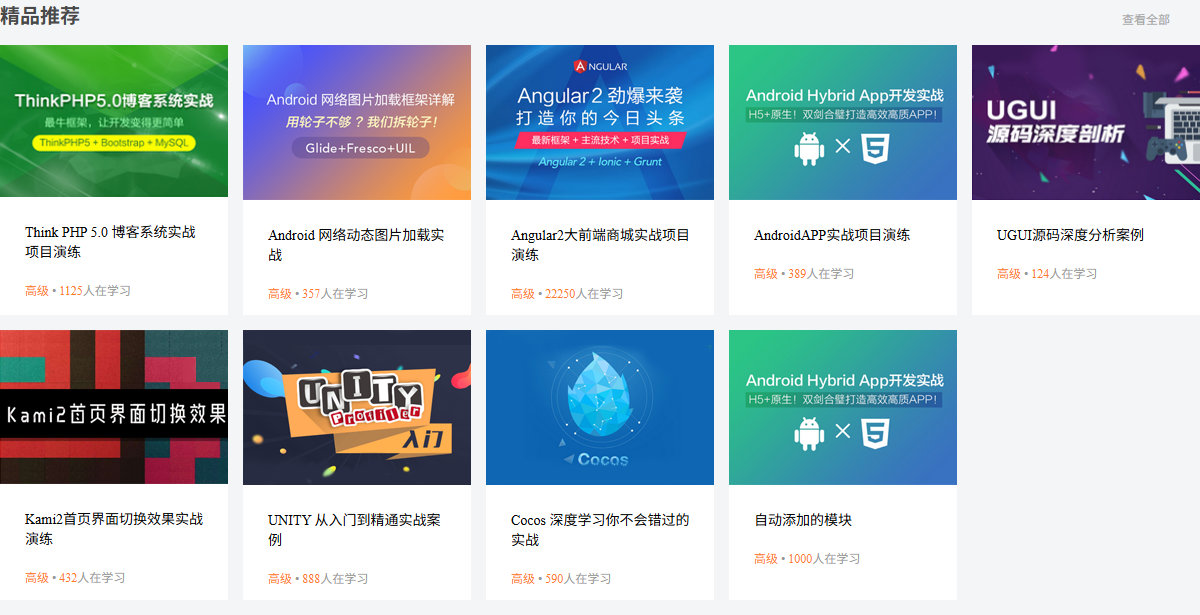

循环在列表内部执行，每轮读取 `data[i]`，写入一个 `<li>`。图片与样式分别在原目录的 `images/` 和 `css/style.css` 中；仅复制 HTML 而没有这些配套文件，图片和样式不会完整显示。

配套原样式：

配套原代码（`04-code/综合作业素材/css/style.css`）：

```css
* {
    margin: 0;
    padding: 0;
}
.w {
    width: 1200px;
    margin: auto;
}
body {
    background-color: #f3f5f7;
}
li {
    list-style: none;
}
a {
    text-decoration: none;
}
.clearfix:before,.clearfix:after {
    content:"";
    display:table; 
  }
  .clearfix:after {
    clear:both;
  }
  .clearfix {
     *zoom:1;
  }   
 

.box {
    margin-top: 30px;
}
.box-hd {
    height: 45px;
}
.box-hd h3 {
    float: left;
    font-size: 20px;
    color: #494949;
}
.box-hd a {
    float: right;
    font-size: 12px;
    color: #a5a5a5;
    margin-top: 10px;
    margin-right: 30px;
}
/* 把li 的父亲ul 修改的足够宽一行能装开5个盒子就不会换行了 */
.box-bd ul {
    width: 1225px;
}
.box-bd ul li {
    position: relative;
    top: 0;
    float: left;
    width: 228px;
    height: 270px;
    background-color: #fff;
    margin-right: 15px;
    margin-bottom: 15px;
    transition: all .3s;
   
}
.box-bd ul li a {
    display: block;
}
.box-bd ul li:hover {
    top: -8px;
    box-shadow: 0 15px 30px rgb(0 0 0 / 10%);
}
.box-bd ul li img {
    width: 100%;
}
.box-bd ul li h4 {
    margin: 20px 20px 20px 25px;
    font-size: 14px;
    color: #050505;
    font-weight: 400;
}
.box-bd .info {
    margin: 0 20px 0 25px;
    font-size: 12px;
    color: #999;
}
.box-bd .info span {
    color: #ff7c2d;
}
```

样式将课程项设置为 `228px` 宽，父列表为 `1225px`，每行容纳五项；悬停时通过 `top` 与阴影突出当前项。此处保留原来的固定宽度样式，重点是把上一阶段 HTML/CSS 的结构与本阶段的数组渲染联系起来。

### 7.3 原码细节与复现检查

原 HTML 的 `<title>` 写成「学车在线首页」，讲义案例名称是「学成在线」，二者按来源保留。原模板的 `src=${data[i].src}` 没有引号，本例路径没有空格，仍可显示；整理模板建议给属性值加引号，并补充 `alt`：

```javascript
let course = {
  src: 'images/course01.png',
  title: 'Think PHP 5.0 博客系统实战项目演练',
  num: 1125
}
document.write(`
  <li>
    <a href="#">
      <img src="${course.src}" title="${course.title}" alt="${course.title}">
      <h4>${course.title}</h4>
      <div class="info"><span>高级</span> · <span>${course.num}</span>人在学习</div>
    </a>
  </li>
`)
```

这段是单项模板示例，实际页面仍把它放进 `<ul>` 并在循环中使用 `data[i]`。原数据数组每项只有 `src`、`title`、`num`，“高级”是模板中固定的文字；如果每门课的等级不同，需要增加对应数据字段。

复现时检查：是否生成九项，标题和人数是否对应，九张图片是否加载，最后一项是否使用 `course04.png`。图片路径相对于 HTML 文件的位置解析，与 Notebook 放在哪个目录无关。

## 8. 拓展：术语与数据存储

### 8.1 常见术语

| 术语 | 含义 | 示例 |
| --- | --- | --- |
| 关键字 | 在语法中具有特定用途的词 | `let`、`function`、`if`、`return` |
| 保留字 | 语法限制为标识符使用的词，具体限制与上下文有关 | `enum`，严格模式中的部分保留词 |
| 标识符 | 为变量、函数等起的名字 | `students`、`getRandomColor` |
| 表达式 | 求值后产生一个值的代码 | `10 + 3`、`age >= 18` |
| 语句 | 执行某个操作或控制流程的代码单位 | `if (...) { ... }`、`for (...) { ... }` |

讲义第 48 页用 `int`、`short`、`long`、`char` 举保留字例子，这沿用了旧式资料；它们在现代 JavaScript 中不能一概当作当前保留字。学习时以所用语法环境为准，也不要把其他语言的类型关键字直接套到 JavaScript。

### 8.2 基本类型与对象

本阶段学习的基本类型有 `number`、`string`、`boolean`、`undefined`、`null`；现代 JavaScript 还有 `symbol`、`bigint`，本日不展开。普通对象、数组和函数属于对象一类。

讲义称对象为“引用类型”，用“变量保存引用，对象数据位于另一处”解释赋值共享。对象字面量 `{}`、数组字面量 `[]` 也会创建对象，并非只有通过 `new` 创建的值才具有引用共享行为。

讲义第 50–52 页的“栈保存值或引用、堆保存对象”是帮助理解的示意模型。具体存储与优化由 JavaScript 引擎实现决定，不是语言规定的每种值固定存放位置；对象内存通常由垃圾回收管理，无需写手动释放语句。本日应掌握的是下面可观察的赋值行为。

### 8.3 复制数值与共享对象

课堂原代码（`04-code/14-数据类型存储.html`）：

```javascript
    let num1 = 10
    let num2 = num1
    num2 = 20
    console.log(num1) // 结果是？


    let obj1 = {
      age: 18
    }
    let obj2 = obj1
    // 修改属性
    obj2.age = 20
    console.log(obj1.age)
  
```

原码依次输出 `10`、`20`：

1. `num2 = num1` 复制数值 `10`；再把 `num2` 改为 `20`，`num1` 仍是 `10`。
2. `obj2 = obj1` 让两个变量指向同一个对象；通过 `obj2.age = 20` 修改属性，`obj1.age` 也读到 `20`。

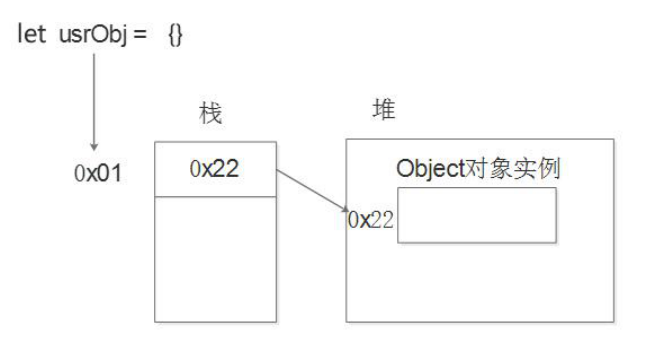

图中的 `0x01`、`0x22` 是示意地址，用来表示引用与对象的关系，不是 JavaScript 代码可直接读取的实际内存地址。

**赋值给另一个对象变量，不会自动复制出一份独立对象。**但重新给其中一个变量赋另一个对象，与修改共享对象属性是两回事，补充示例：

```javascript
let obj1 = { age: 18 }
let obj2 = obj1
console.log(obj1 === obj2)  // true，同一对象
obj2.age = 20
console.log(obj1.age)       // 20，共享对象被修改
obj2 = { age: 30 }
console.log(obj1.age)       // 20，obj2 改为指向另一个对象
console.log(obj2.age)       // 30
console.log(obj1 === obj2)  // false
```

传对象给函数时也传入这个引用值的副本：函数可以通过它修改同一对象的属性，但在函数内给形参重新赋一个新对象，并不会让调用者的变量自动改指向。不要把它误理解成函数可以任意替换外部对象变量。

## 9. 配套作业：题目、参考与修正

当天有五道基础练习、两道拓展作业、两道排错题。客观题使用资料中的[第五天作业链接](https://ks.wjx.top/vm/hgfFlVd.aspx#)。先独立尝试，再对照原参考和整理写法；资料没有给出具体代码的题目，按课堂方法补齐。

### 9.1 基础题一：随机点名后删除

要求：每次运行在控制台随机输出 `['老赵', '老李', '小传', '小黑']` 中一位同学，再删除这个名字。原答案只提示使用课堂方法，没有具体代码。整理参考：

```javascript
let names = ['老赵', '老李', '小传', '小黑']
let index = Math.floor(Math.random() * names.length)
console.log(names[index])
names.splice(index, 1)
console.log(names)
```

删除后剩三项，且不再包含刚抽中的同学。刷新网页会重新初始化名单；本题没有存储机制，不能保证不同刷新之间不重复。

### 9.2 基础题二：声明对象并调用属性和方法

要求：声明对象 `per`，含性别、年龄、爱好三个属性，及说话、吃饭两个方法，在控制台读取属性并调用方法。资料参考答案：

资料参考答案：

```javascript
let per = {
  sex: 'man', // 年龄,
  age: 18, // 性别,
  hobby: 'studyAndGame', // 爱好
   speak: function () {
    // 说话,
     document.write(`speak方法被调用了--- <br>`)
   },
   eat: function () {
    // 吃饭
     document.write(`eat方法被调用了---`)
   }
}
// 下面是调用部分
document.write(`姓名:${per.sex} <br>`)
document.write(`姓名:${per.age}<br>`)
document.write(`姓名:${per.hobby}<br>`)
// 调用方法
per.speak()
per.eat()
```

**原参考的差异：**`sex`、`age` 的注释颠倒，三个属性输出都写成了“姓名”；输出位置实际是页面而非题目要求的控制台。代码仍能执行，方法也会被调用，但阅读时应按属性本义理解。

符合题目输出位置的整理版：

```javascript
let per = {
  sex: '男',
  age: 18,
  hobby: '学习和游戏',
  speak: function () {
    console.log('说话方法被调用了')
  },
  eat: function () {
    console.log('吃饭方法被调用了')
  }
}
console.log(per.sex)
console.log(per.age)
console.log(per.hobby)
per.speak()
per.eat()
```

### 9.3 基础题三：调用带参数的方法

要求：调用对象的吃饭方法，并可以传入参数。资料参考答案：

资料参考答案：

```javascript
let per = {
  sex: 'man', // 年龄,
  age: 18, // 性别,
  hobby: 'studyAndGame', // 爱好
  speak: function () {
    // 说话,
     document.write(`speak方法被调用了---<br>`)
   },
   eat: function (f) {
    // 吃饭
    document.write(`我今天吃的是${f}`)
   }
}
// 下面是调用部分
document.write(`姓名:${per.sex} <br>`)
document.write(`姓名:${per.age}<br>`)
document.write(`姓名:${per.hobby}<br>`)

// 调用方法
per.speak()
per.eat('苹果')
```

`per.eat('苹果')` 把字符串传给形参 `f`，页面显示 `我今天吃的是苹果`。方法调用仍然是函数调用，参数规则没有改变。原参考中属性的注释与输出标签问题和上一题相同。

若需要控制台输出，整理示例：

```javascript
let per = {
  eat: function (food) {
    console.log(`我今天吃的是${food}`)
  }
}
per.eat('苹果')
```

### 9.4 基础题四：最多猜八次

题目只要求最多八次。资料参考答案采用 `0~20`，与课堂的 `1~10` 范围不同；它使用 `for` 控制次数，猜对提前结束：

资料参考答案：

```javascript
 function random(min, max) {

      return Math.floor(Math.random() * (max - min + 1)) + min
}
    // 生成一个数字先,猜0-20之间的数
    let num = random(0, 20)

    let flag = true
    // 最多猜8次
    for (let i = 1; i <= 8; i++) {

      let userNum = prompt('请输入您要猜的数字')

      // 比较数字
      if (userNum > num) {

        alert('您猜的数字大了')
      } else if (userNum < num) {

        alert('您猜的数字小了')
      } else {
        flag = false
        alert('恭喜猜对了！')
        break
      }
    }

    if (flag) {
      alert('太笨了，这都猜不到！O(∩_∩)O')
    }
```

原参考的 `prompt` 没有显式转数字，和数字做 `>`、`<` 比较时会隐式转换。非法文字会使两次比较都为假，误进入猜对分支。取消或空字符串会转换为 `0`，当目标恰好为 `0` 时也可能被当成猜对。

下面保留参考的 `0~20` 范围，补充输入校验、取消退出和明确的成功判断。**最多八次有效猜测**，非法输入不占次数，这是整理版明确采用的规则：

```javascript
let target = Math.floor(Math.random() * 21)
let attempts = 0
let won = false
let cancelled = false
while (attempts < 8) {
  let input = prompt(`第${attempts + 1}次：请输入0~20之间的整数`)
  if (input === null) {
    cancelled = true
    break
  }
  let num = Number(input)
  if (input.trim() === '' || !Number.isInteger(num) || num < 0 || num > 20) {
    alert('请输入有效的0~20整数')
    continue
  }
  attempts++
  if (num === target) {
    won = true
    alert('猜对了')
    break
  }
  alert(num > target ? '您猜大了' : '您猜小了')
}
if (!won && !cancelled) {
  alert(`八次机会已经用完，答案是${target}`)
}
```

在第八次猜对时只提示成功；八次有效输入均未猜对才提示次数用完；取消后不显示失败。想沿用课堂范围，只需把目标改为 `Math.floor(Math.random() * 10) + 1`，同时将校验范围改成 `1~10`。

### 9.5 基础题五：重写随机颜色

原作业答案只提示重写课堂案例，没有新增实现。完整原代码见第 6.3 节。独立写时按下面顺序自查：

1. 默认参数为 `true`，省略参数返回十六进制。
2. 十六进制字符串以 `#` 开头，循环六次，每次选择 `0~15` 的字符索引。
3. RGB 的三个通道分别选择 `0~255`，乘数应为 `256`。
4. 两个分支都用 `return`，由调用者决定如何显示。
5. 同时验证 `getRandomColor()`、`getRandomColor(true)`、`getRandomColor(false)`。

不能只在函数内部 `console.log` 就认为已经返回了颜色，也不能把六个字符缩减成一次抽取。

### 9.6 拓展作业一：英雄列表与姓名提示

要求：根据对象数组渲染多张英雄图片，鼠标经过停留时显示英雄名字。原数据包含 20 项，后六个名字用 `XXX` 占位。本篇保留占位，不凭图片猜补姓名。

配套已完成的原页面：

配套原代码（`05-作业/答案/拓展作业/英雄列表案例/hero(学生练习).html`）：

```html
<!DOCTYPE html>
<html lang="en">

<head>
	<meta charset="UTF-8">
	<meta name="viewport" content="width=device-width, initial-scale=1.0">
	<meta http-equiv="X-UA-Compatible" content="ie=edge">
	<title>渲染英雄列表案例</title>
	<link rel="stylesheet" href="css/hero.css">
</head>

<body>
	<!-- 利用对象数组渲染英雄列表案例 -->
	<!-- <ul class="list">
		
	</ul> -->
	<script>
		const datas = [
			{ name: '司马懿', imgSrc: '01.jpg' },
			{ name: '女娲', imgSrc: '02.jpg' },
			{ name: '百里守约', imgSrc: '03.jpg' },
			{ name: '亚瑟', imgSrc: '04.jpg' },
			{ name: '虞姬', imgSrc: '05.jpg' },
			{ name: '张良', imgSrc: '06.jpg' },
			{ name: '安其拉', imgSrc: '07.jpg' },
			{ name: '李白', imgSrc: '08.jpg' },
			{ name: '阿珂', imgSrc: '09.jpg' },
			{ name: '墨子', imgSrc: '10.jpg' },
			{ name: '鲁班', imgSrc: '11.jpg' },
			{ name: '嬴政', imgSrc: '12.jpg' },
			{ name: '孙膑', imgSrc: '13.jpg' },
			{ name: '周瑜', imgSrc: '14.jpg' },
			{ name: 'XXX', imgSrc: '15.jpg' },
			{ name: 'XXX', imgSrc: '16.jpg' },
			{ name: 'XXX', imgSrc: '17.jpg' },
			{ name: 'XXX', imgSrc: '18.jpg' },
			{ name: 'XXX', imgSrc: '19.jpg' },
			{ name: 'XXX', imgSrc: '20.jpg' }
		]

		let str = ''
		for (let i = 0; i < datas.length; i++) {
			str += `
				<li><img src="./uploads/heros/${datas[i].imgSrc}" title="${datas[i].name}"></li>
			`
		}
		document.write(`
		<ul class="list">
			${str}
		</ul>
		`)
	</script>
</body>

</html>
```

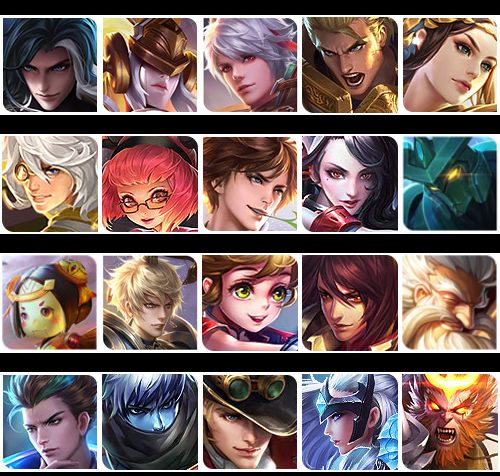

原 CSS：

配套原代码（`05-作业/答案/拓展作业/英雄列表案例/css/hero.css`）：

```css
* {
  margin: 0;
  padding: 0;
}

ul {
  list-style: none;
}

a {
  width: 150px;
  height: 30px;
  text-decoration: none;
  display: block;
  margin: 10px auto;
  background: goldenrod;
  color: #fff;
  border-radius: 15px;
  line-height: 30px;
}

a:hover {
  background: gold;
  color: #666;
}

body {
  background: #000;
  text-align: center;
}

.list {
  display: flex;
  flex-wrap: wrap;
  width: 500px;
  margin: 20px auto;
}

.list li {
  position: relative;
  transition: all 1s;
  margin-top: 15px;
}

.list li:first-child {
  margin-left: 0;
}

.list li:hover {
  transform: scale(1.3);
  z-index: 999;
}

.list li img {
  width: 100px;
}
```

`datas[i].imgSrc` 提供图片文件名，路径前面拼上 `./uploads/heros/`；`title="${datas[i].name}"` 让浏览器在鼠标停留时显示原生文字提示。CSS 的 `:hover` 放大图片，与 `title` 提示属于两个不同效果。

配套图片目录有 `01.jpg~22.jpg`，当前数据只使用前 20 张。复制页面时应一起保留 `css/hero.css` 和 `uploads/heros/`；检查生成 20 个 `<li>`，每个图片的路径与 `title` 是否对应。原图没有 `alt`，整理网页时可补充对应姓名作为替代文本。

### 9.7 拓展作业二：成绩表、总分与平均分

要求：按数据生成编号、科目、成绩、删除链接四列，计算总分和平均分。数据为语文 `46`、数学 `80`、英语 `100`。原 Markdown 中的参考页面：

资料参考答案：

```html
<!DOCTYPE html>
<html lang="en">

<head>
  <meta charset="UTF-8" />
  <meta http-equiv="X-UA-Compatible" content="IE=edge" />
  <meta name="viewport" content="width=device-width, initial-scale=1.0" />
  <link rel="stylesheet" href="./styles/index.css" />
  <title>Document</title>
</head>

<body>
  <script>
    // 核心数据
    const data = [
      { subject: '语文', score: 46 },
      { subject: '数学', score: 80 },
      { subject: '英语', score: 100 },
    ]
    let tr = ''
    let total = 0 // 计算总分
    for (let i = 0; i < data.length; i++) {
      tr += `
        <tr>
            <td>${i + 1}</td>
            <td>${data[i].subject}</td>
            <td>${data[i].score}</td>
            <td><a href="#">删除</a></td>
        </tr>
      `
      total += data[i].score
    }
    document.write(`
    <div id="app" class="score-case">
      <div class="table">
        <table>
          <thead>
            <tr>
              <th>编号</th>
              <th>科目</th>
              <th>成绩</th>
              <th>操作</th>
            </tr>
          </thead>
          <tbody>
            ${tr}
          </tbody>
          <tbody>
            <tr>
              <td colspan="5">
                <span class="none">暂无数据</span>
              </td>
            </tr>
          </tbody>

          <tfoot>
            <tr>
              <td colspan="5">
                <span>总分：${total}</span>
                <span style="margin-left: 50px">平均分：${total / data.length}</span>
              </td>
            </tr>
          </tfoot>
        </table>
      </div>

    </div>
    `)
  </script>
</body>

</html>
```

**参考答案与静态模板需要区分：**动态计算结果是总分 `226`、平均分 `226 / 3`（约 `75.3333`）。配套静态模板里写死的总分 `246`、平均分 `79` 不对应这组数据，完成时应以数组计算结果为准。

原参考还保留了始终输出的“暂无数据”行，有数据时也会显示；表格实际四列，却把合并单元格写为 `colspan="5"`。删除只是 `<a href="#">` 链接，没有删除数据的事件逻辑；本日任务是渲染链接，不是完成交互删除。

下面是修正列数与空状态的整理版。放入配套成绩表 HTML 的 `<script>` 中，并保留它原来的 `styles/index.css` 引用；删除静态表格，避免重复显示：

```javascript
const data = [
  { subject: '语文', score: 46 },
  { subject: '数学', score: 80 },
  { subject: '英语', score: 100 }
]
let rows = ''
let total = 0
for (let i = 0; i < data.length; i++) {
  rows += `
    <tr>
      <td>${i + 1}</td>
      <td>${data[i].subject}</td>
      <td>${data[i].score}</td>
      <td><a href="#">删除</a></td>
    </tr>
  `
  total += data[i].score
}
if (data.length === 0) {
  rows = '<tr><td colspan="4"><span class="none">暂无数据</span></td></tr>'
}
let average = data.length > 0 ? total / data.length : '暂无'
document.write(`
  <div id="app" class="score-case">
    <div class="table">
      <table>
        <thead><tr><th>编号</th><th>科目</th><th>成绩</th><th>操作</th></tr></thead>
        <tbody>${rows}</tbody>
        <tfoot><tr><td colspan="4">
          <span>总分：${total}</span>
          <span style="margin-left: 50px">平均分：${average}</span>
        </td></tr></tfoot>
      </table>
    </div>
  </div>
`)
```

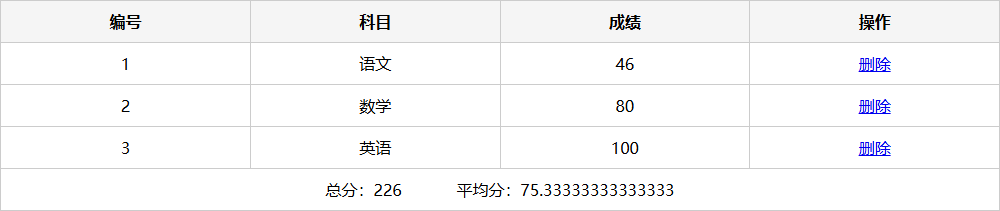

空数组时总分为 `0`，平均分显示“暂无”，避免 `0 / 0` 得到 `NaN`；非空时只显示数据行。按题目保留原始平均数，没有擅自四舍五入成整数。

### 9.8 排错题一：属性访问与拼写

原题代码有两个错误：

作业原题代码：

```html
<!-- bug:请你找到下面代码的2处BUG进行修改 -->

<body>
  <script>
    let obj = {
      name: '张三',
      age: 20,
      sex: '男',
      address: '中国人'
    }
    // 获取姓名
    console.log(obj.['name']);

    // 获取地址
    console.log(obj.addres);
  </script>
</body>
```

`obj.['name']` 是语法错误，整个脚本解析失败，之前的语句也不会执行；正确写法为 `obj['name']` 或 `obj.name`。修正第一处之后，`obj.addres` 因拼错名字得到 `undefined`，应改为 `obj.address`。

修正代码：

```javascript
let obj = {
  name: '张三',
  age: 20,
  sex: '男',
  address: '中国人'
}
console.log(obj['name'])  // 张三
console.log(obj.address)  // 中国人
```

### 9.9 排错题二：逗号、方法调用与参数

原题代码：

作业原题代码：

```html
<!-- 请你找到下面代码的3处bug进行修改 -->

<body>
  <script>
    let obj = {
      name: '张三',
      age: 20,
      sex: '男',
      address: '中国人',
      sing: function () {
        console.log('我会唱歌')
      }
      sum: function (x, y) {
       return x + y
      }
    }

    console.log(obj.sing)
    console.log(obj.sum)
  </script>
</body>
```

`sing` 成员后缺少逗号，导致语法错误；先补逗号才能执行。`console.log(obj.sing)` 和 `console.log(obj.sum)` 只是输出函数本身，没有调用方法，这在语法上合法，但不满足题目执行方法的意图。

修正代码应给方法加调用括号；`sum` 还需要传入两个有效数字，否则 `undefined + undefined` 仍然得到 `NaN`：

```javascript
let obj = {
  name: '张三',
  age: 20,
  sex: '男',
  address: '中国人',
  sing: function () {
    console.log('我会唱歌')
  },
  sum: function (x, y) {
    return x + y
  }
}
obj.sing()                  // 输出：我会唱歌
console.log(obj.sum(1, 2))   // 输出：3
```

`sing` 在内部输出，没有返回值，不需要再包一层 `console.log`；否则还会多输出一个 `undefined`。`sum` 返回结果，因此由外层输出它。

## 10. 复习与自查

### 10.1 今日知识清单

| 知识点 | 应能独立完成的内容 |
| --- | --- |
| 对象声明 | 花括号、键值对、冒号与逗号 |
| 属性访问 | 固定名字用点，动态名字或特殊名字用方括号 |
| 增删改查 | 根据同一属性名赋值、读取与删除 |
| 方法 | 访问函数与调用函数的区别，传参和返回值 |
| 遍历对象 | `k` 是属性名，`obj[k]` 是属性值 |
| 对象数组 | 先取 `arr[i]`，再取对象属性 |
| 数据渲染 | 静态容器与循环生成的重复项分开 |
| Math | 数轴上的取整方向、极值、绝对值、幂与平方根 |
| 随机整数 | 闭区间公式、数组合法索引范围 |
| 随机点名 | 抽中后删除，剩余长度随抽取变化 |
| 猜数字 | 答案生成在循环外，校验输入，明确退出条件 |
| 随机颜色 | 十六进制六个字符、RGB 三个独立通道 |
| 赋值行为 | 基本值复制，对象变量可以共享同一对象 |

### 10.2 快速问答

1. 属性名和值之间用什么符号？答案：英文冒号 `:`。
2. `obj[k]` 与 `obj.k` 一样吗？答案：前者使用变量值作为键，后者访问固定的 `k` 属性。
3. `obj.name` 能修改 `obj['goods-name']` 吗？答案：不能，它们是不同键。
4. `obj.eat` 和 `obj.eat()` 有何区别？答案：前者取得函数，后者调用函数。
5. `Math.floor('12px')` 与 `parseInt('12px')` 分别是什么？答案：`NaN`、`12`。
6. `Math.floor(-1.1)`、`Math.ceil(-1.1)` 分别是什么？答案：`-2`、`-1`。
7. 随机 `N~M` 的公式为什么有 `+1`？答案：两端都包含时共有 `M - N + 1` 个整数。
8. 原猜数字代码为什么可能把 `'abc'` 当成猜对？答案：转换后是 `NaN`，两次大小比较均为假。
9. 删除抽中的姓名后刷新，名单还会保持吗？答案：不会，数组声明重新执行。
10. `obj2 = obj1` 后修改 `obj2.age`，`obj1.age` 会怎样？答案：两个变量共享同一对象，读到修改后的值。
11. 成绩 `46、80、100` 的总分是多少？答案：`226`，平均分为 `226 / 3`。
12. 生成了“删除”链接就已经能删除数据了吗？答案：没有，还需要后续的事件处理和更新逻辑。

### 10.3 复习路线与资料索引

讲义第 54 页建议：梳理对象知识，独立重写学成在线案例和随机颜色，再完成[第五天课堂测试](https://ks.wjx.top/vj/tHu7X7y.aspx)与课后作业，整理五天基础知识，准备下一阶段实战。该页把作业目录写作“06-作业”，实际资料目录是 `05-作业`。

| 原资料 | 对应内容 |
| --- | --- |
| 讲义 5–13 页 | 对象用途、声明、属性与商品练习 |
| 讲义 14–26 页 | 增删改查、方括号、方法与调用 |
| 讲义 28–33 页 | 遍历对象、对象数组与学生表 |
| 讲义 35–38 页 | Math 与随机整数公式 |
| 讲义 39–44 页 | 点名、猜数字、随机颜色 |
| 讲义 46–47 页 | 学成在线课程列表渲染 |
| 讲义 48–53 页 | 术语、基本类型与对象赋值 |
| `03-笔记/README.md`、`02-Xmind/js基础第五天.xmind` | 基础概念、Math 补充与知识结构 |
| `04-code` 中 13 份编号 HTML | 全部课堂原代码与实际执行说明 |
| `04-code/综合作业素材` | 已完成的九项课程列表、CSS 与图片 |
| `06-素材/学生信息表素材.html`、`06-素材/综合作业素材` | 静态练习模板与八条初始课程数据 |
| `05-作业/题目/作业.md`、`05-作业/答案/作业.md` | 五道基础题、两道拓展题、两道排错题 |
| `05-作业/答案/拓展作业` | 英雄页面、成绩页面及样式图片 |

复习时先明确每段代码的数据来源、循环对象、输出结构和边界，再对照执行结果；随机结果可以变化，结构与取值范围必须正确。